Task 1: Load the data
This downloads the heart disease data from UCI and puts it in a table. The target column num is 0 for no disease and 1 to 4 for different levels of disease, so i turn it into 0 or 1.

In [12]:
!pip install ucimlrepo
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

heart = fetch_ucirepo(id=45)
df = heart.data.features.copy()
df["target"] = (heart.data.targets["num"] > 0).astype(int)
print(df.shape)

(303, 14)


Task 2: Look at the data
What it does: shows the first rows, the column types, and basic stats (average, min, max) so you know what you’re working with.

In [13]:
df.head()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


Task 3: Missing Values. In this step I count the blanks in each column. Some datasets hide missing values as "?" instead of leaving them empty, so I swap those for real blanks first. Then I fill the gaps, using the median for number columns and the most common value for category columns.

In [14]:
df = df.replace("?", np.nan)
print(df.isnull().sum())

from sklearn.impute import SimpleImputer

num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

df[num_cols] = df[num_cols].apply(pd.to_numeric)

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


Task 4: Build the Pipeline. In this step I split the data into a training set and a test set first, so the test data stays unseen until I go over it. Then I build one automatic prep line with a ColumnTransformer. The number columns get their blanks filled with the median and are scaled to a similar size, so no column dominates just because its numbers are bigger. The category columns get their blanks filled with the most common value and are turned into 0/1 columns with OneHotEncoder, so the model doesn’t treat category numbers like amounts.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())])
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))])

preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)])

print(X_train.shape, X_test.shape)

(242, 13) (61, 13)


Task 5: Support Vector Classifier. In this step I train an SVC with an RBF kernel inside the pipeline, so the prep steps run automatically on the data before the model sees it. I set probability=True so the model can give a chance of disease for each patient. Then I grade it three ways. The confusion matrix shows how many patients it got right and wrong in each group. The classification report shows precision and recall. The ROC curve and ROC-AUC score show how well the model separates sick patients from healthy ones, where a score closer to 1 is better. I write the grading as a function so I can reuse it for the Decision Tree in Task 6.

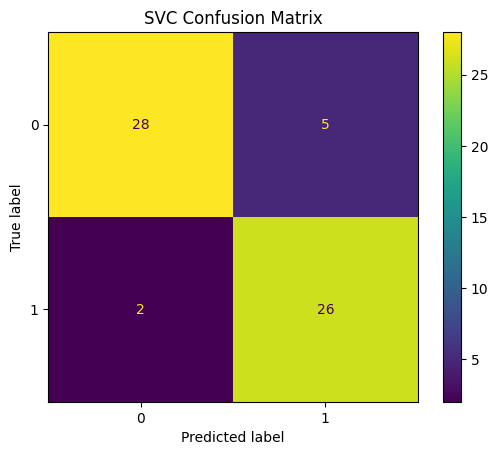

              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

ROC-AUC: 0.9642857142857143


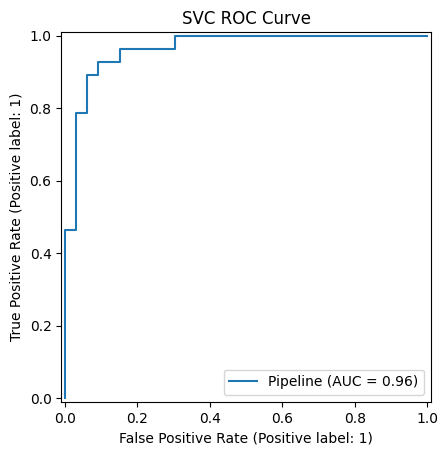

In [16]:
from sklearn.svm import SVC
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_auc_score, RocCurveDisplay)
import matplotlib.pyplot as plt

svc_pipe = Pipeline([("prep", preprocess),
                     ("model", SVC(kernel="rbf", probability=True, random_state=42))])
svc_pipe.fit(X_train, y_train)

def evaluate(pipe, name):
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot()
    plt.title(f"{name} Confusion Matrix"); plt.show()
    print(classification_report(y_test, pred))
    print("ROC-AUC:", roc_auc_score(y_test, prob))
    RocCurveDisplay.from_estimator(pipe, X_test, y_test)
    plt.title(f"{name} ROC Curve"); plt.show()

evaluate(svc_pipe, "SVC")

Task 6: Decision Tree Classifier. In this step I train a Decision Tree inside the same kind of pipeline, using the same prep steps and the same grading function as the SVC so the comparison is fair. A Decision Tree works by asking a series of yes or no questions about the patient, like whether their maximum heart rate is above a certain number, until it reaches a prediction. I limit it to a depth of 4 so it doesn’t memorize the training data and stays easy to read.

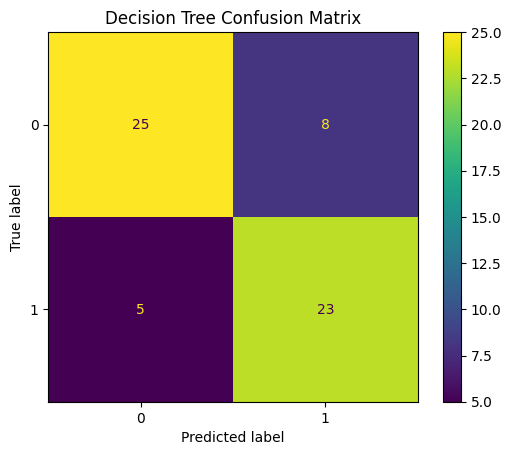

              precision    recall  f1-score   support

           0       0.83      0.76      0.79        33
           1       0.74      0.82      0.78        28

    accuracy                           0.79        61
   macro avg       0.79      0.79      0.79        61
weighted avg       0.79      0.79      0.79        61

ROC-AUC: 0.8598484848484849


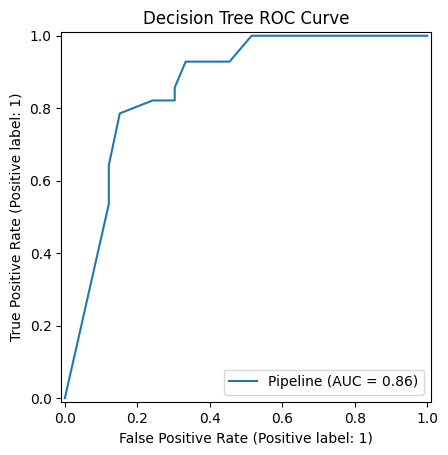

In [17]:
from sklearn.tree import DecisionTreeClassifier

tree_pipe = Pipeline([("prep", preprocess),
                      ("model", DecisionTreeClassifier(max_depth=4, random_state=42))])
tree_pipe.fit(X_train, y_train)
evaluate(tree_pipe, "Decision Tree")

Task 7: Tune the SVC with GridSearchCV. In this step I try to improve the SVC by testing different settings. C controls how strict the model is about getting every training patient right, and gamma controls how closely the model hugs the training data. GridSearchCV tries every combination of the values I give it and checks each one with 5 fold cross validation, which means it splits the training data into 5 parts and rotates which part is used for testing. This gives a more reliable score than a single split. I score each combination with ROC-AUC and keep the best one, then grade that tuned model on the test set with the same function as before.

Best settings: {'model__C': 1, 'model__gamma': 0.01}
Best CV score: 0.8882830535004448


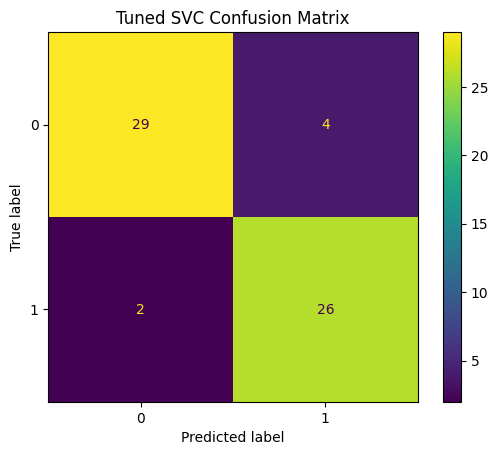

              precision    recall  f1-score   support

           0       0.94      0.88      0.91        33
           1       0.87      0.93      0.90        28

    accuracy                           0.90        61
   macro avg       0.90      0.90      0.90        61
weighted avg       0.90      0.90      0.90        61

ROC-AUC: 0.9675324675324675


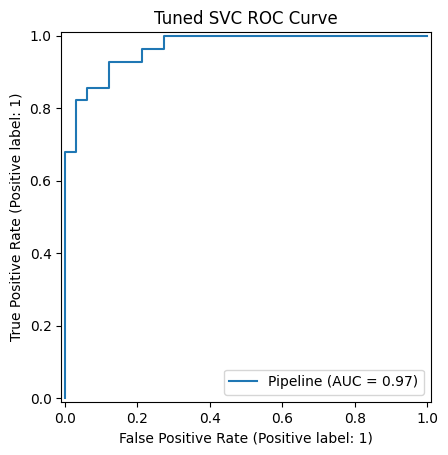

In [18]:
from sklearn.model_selection import GridSearchCV

param_grid = {"model__C": [0.1, 1, 10, 100],
              "model__gamma": ["scale", 0.01, 0.1, 1]}
grid = GridSearchCV(svc_pipe, param_grid, cv=5, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best CV score:", grid.best_score_)
evaluate(grid.best_estimator_, "Tuned SVC")

Task 8: Interpret the Decision Tree. In this step I look inside the Decision Tree to see how it separates patients with heart disease from healthy patients. First I pull out feature importances, which score how much each clinical feature helped the tree make its decisions. A higher score means the tree relied on that feature more. The category columns appear as separate 0/1 columns because of the encoding in the pipeline. Then I draw the tree with plot_tree so I can follow the exact yes or no questions it asks, from the top of the tree down to a final prediction.

cat__thal_3.0     0.442083
cat__cp_4.0       0.159846
cat__ca_0.0       0.138960
num__oldpeak      0.078337
num__chol         0.070772
cat__sex_1.0      0.031083
num__age          0.027424
cat__slope_1.0    0.024356
num__thalach      0.023401
cat__thal_7.0     0.003738
dtype: float64


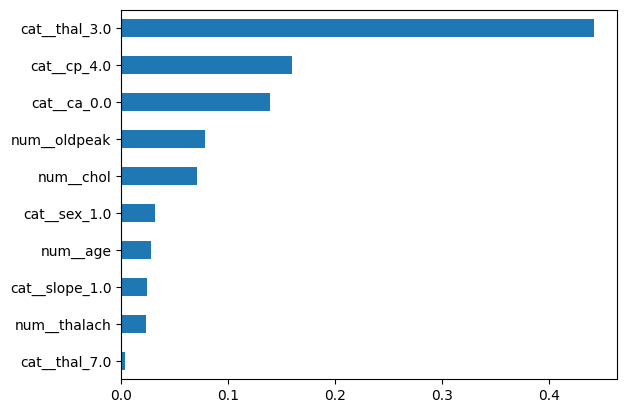

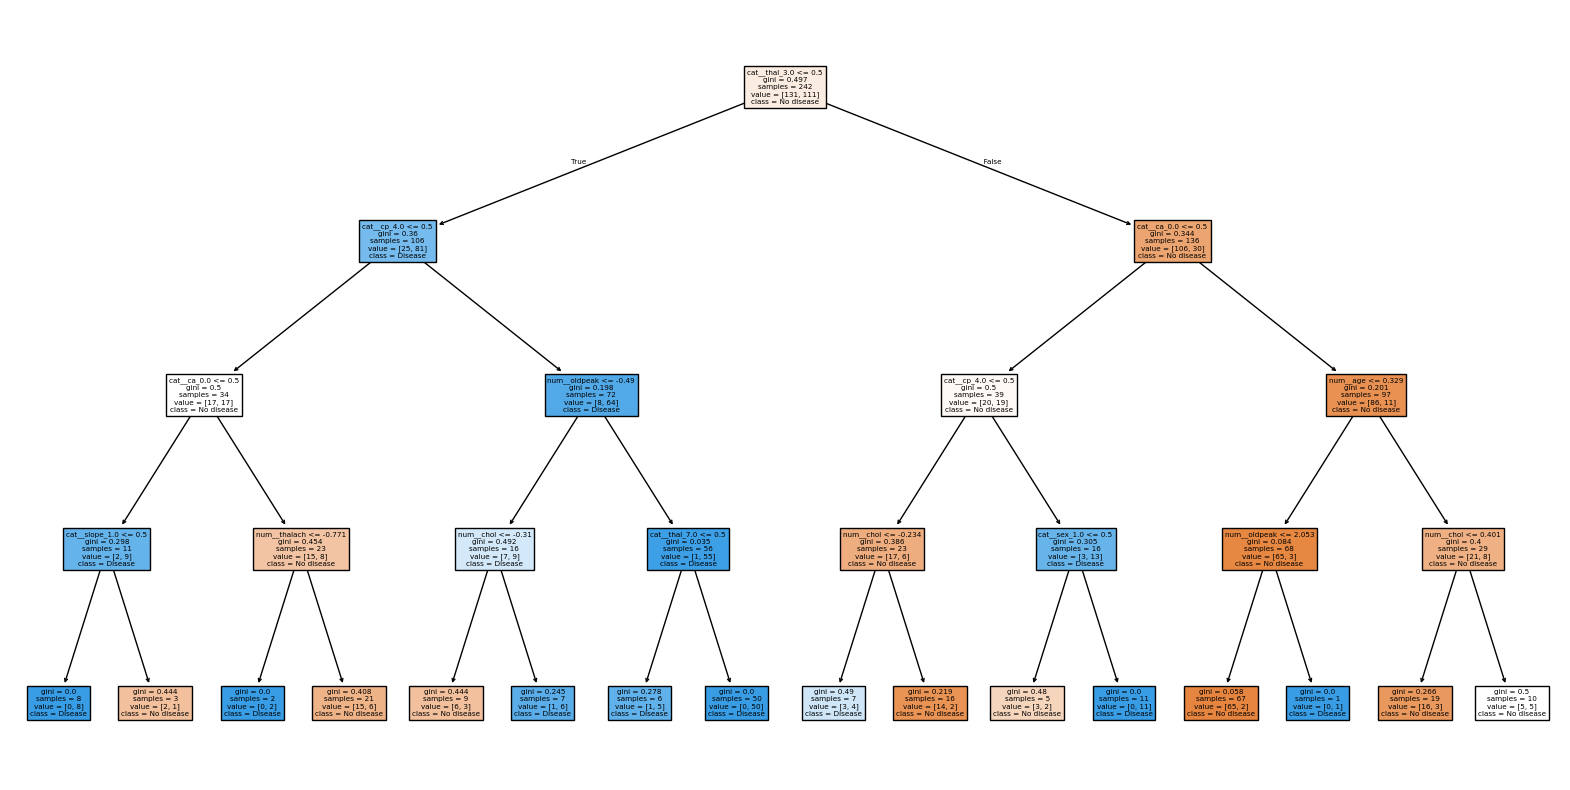

In [19]:
from sklearn.tree import plot_tree

tree = tree_pipe.named_steps["model"]
names = tree_pipe.named_steps["prep"].get_feature_names_out()

imp = pd.Series(tree.feature_importances_, index=names).sort_values(ascending=False)
print(imp.head(10))
imp.head(10).plot(kind="barh"); plt.gca().invert_yaxis(); plt.show()

plt.figure(figsize=(20, 10))
plot_tree(tree, feature_names=names, class_names=["No disease", "Disease"], filled=True)
plt.show()